In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report,roc_auc_score)

In [27]:
df = pd.read_csv("bank-additional-full.csv", sep=";")
df.head()
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
df.info()
df.describe()

Number of rows: 41188
Number of columns: 21
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [28]:
df.isnull().sum()

,0
age,0
job,0
marital,0
education,0
default,0
housing,0
loan,0
contact,0
month,0
day_of_week,0


In [29]:
print("Duplicate records:", df.duplicated().sum())
print("Missing Values:", df.isnull().sum().sum())
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)
print(df['y'].value_counts())
df['y'] = df['y'].map({'yes': 1, 'no': 0})
print(df['y'].value_counts())

Duplicate records: 12
Missing Values: 0
Shape after removing duplicates: (41176, 21)
y
no     36537
yes     4639
Name: count, dtype: int64
y
0    36537
1     4639
Name: count, dtype: int64


In [30]:
df = df.drop('duration', axis=1)
print("Duration column removed")
print("New dataset shape:", df.shape)

Duration column removed
New dataset shape: (41176, 20)


In [31]:
for col in df.select_dtypes(include='object').columns:
    print(col, ":", (df[col] == 'unknown').sum())

job : 330
marital : 80
education : 1730
default : 8596
housing : 990
loan : 990
contact : 0
month : 0
day_of_week : 0
poutcome : 0


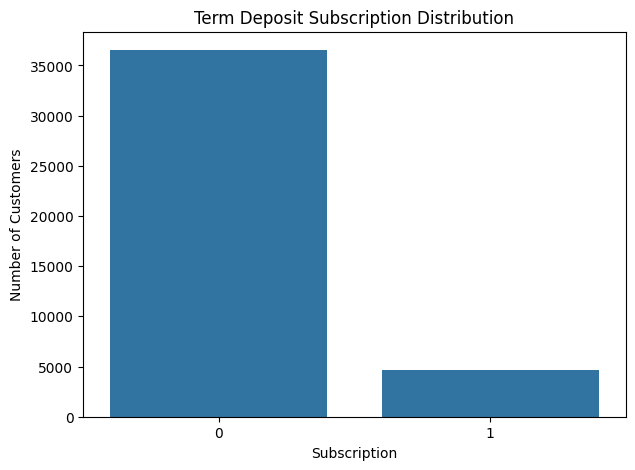

In [32]:
plt.figure(figsize=(7,5))
sns.countplot(data=df, x='y')
plt.title("Term Deposit Subscription Distribution")
plt.xlabel("Subscription")
plt.ylabel("Number of Customers")
plt.show()

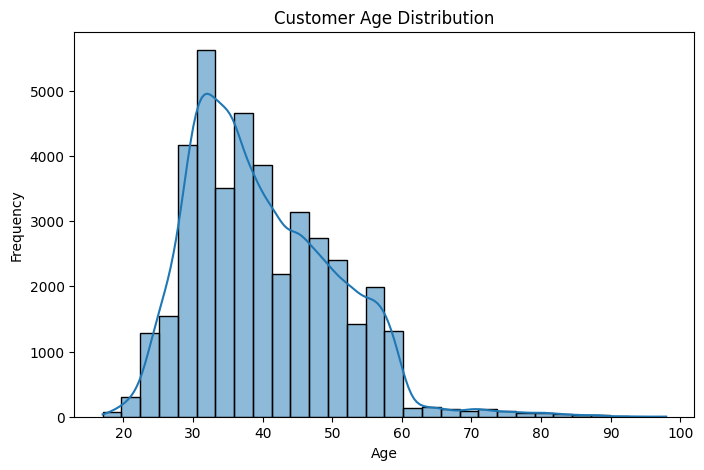

In [33]:
plt.figure(figsize=(8,5))
sns.histplot(df['age'], bins=30, kde=True)
plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

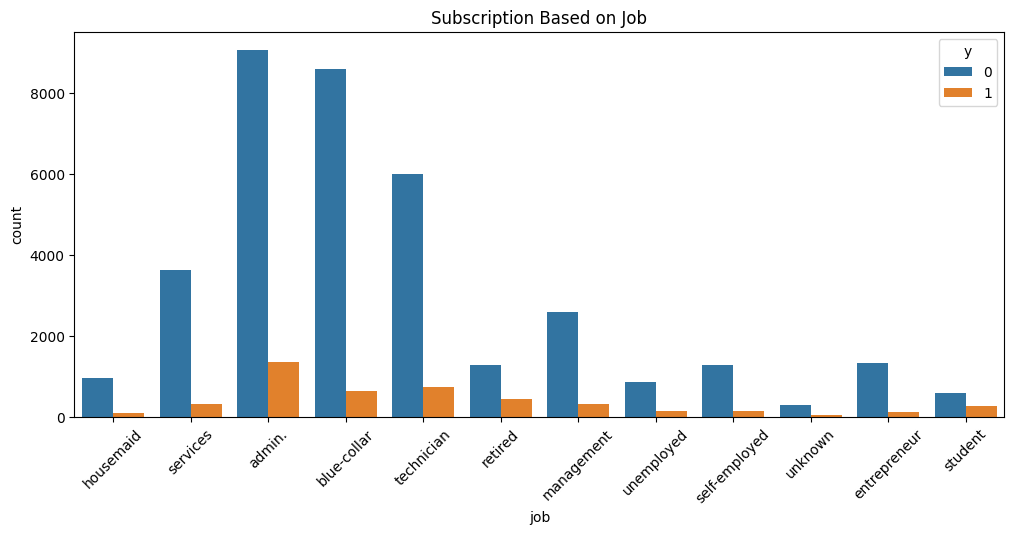

In [34]:
plt.figure(figsize=(12,5))
sns.countplot(data=df, x='job', hue='y')
plt.title("Subscription Based on Job")
plt.xticks(rotation=45)
plt.show()

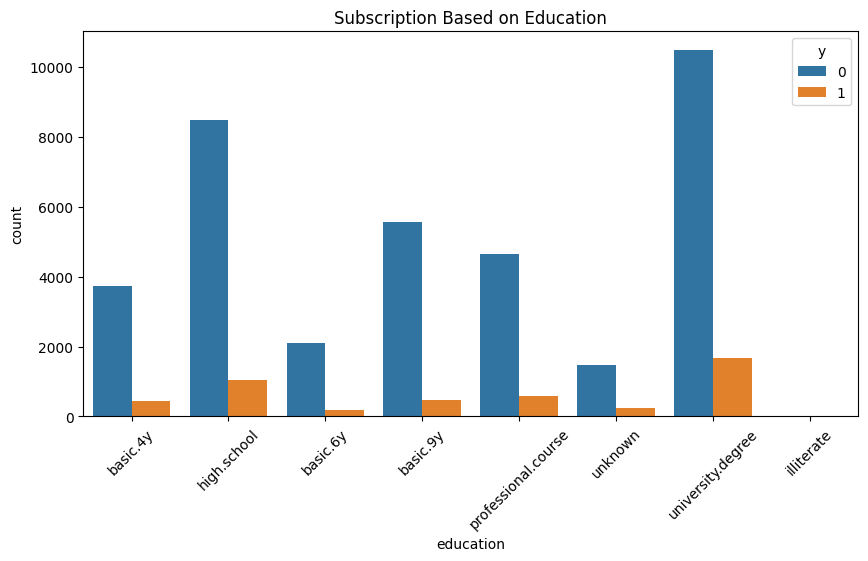

In [35]:
plt.figure(figsize=(10,5))
sns.countplot(data=df, x='education', hue='y')
plt.title("Subscription Based on Education")
plt.xticks(rotation=45)
plt.show()

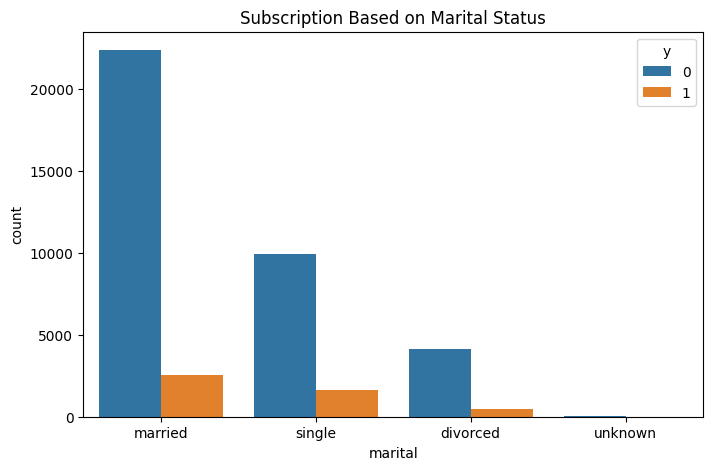

In [36]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='marital', hue='y')
plt.title("Subscription Based on Marital Status")
plt.show()

In [37]:
X = df.drop('y', axis=1)
y = df['y']
print("Independent variables:", X.shape)
print("Target variable:", y.shape)

Independent variables: (41176, 19)
Target variable: (41176,)


In [38]:
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X.select_dtypes(include=['object']).columns
print("Numerical Features:", list(numeric_features))
print("\nCategorical Features:", list(categorical_features))

Numerical Features: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

Categorical Features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


In [39]:
numeric_transformer = Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),('scaler', StandardScaler())])
categorical_transformer = Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),('encoder', OneHotEncoder(handle_unknown='ignore'))])
preprocessor = ColumnTransformer(transformers=[('num', numeric_transformer, numeric_features),('cat', categorical_transformer, categorical_features)])

In [40]:
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.20,random_state=42,stratify=y)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (32940, 19)
Testing data: (8236, 19)


In [41]:
models = {'Logistic Regression': LogisticRegression(max_iter=1000,class_weight='balanced'),

          'Decision Tree': DecisionTreeClassifier(random_state=42, class_weight='balanced'),

          'Random Forest': RandomForestClassifier(n_estimators=100,random_state=42,class_weight='balanced',n_jobs=-1),

          'Gradient Boosting': GradientBoostingClassifier(random_state=42)}
results = []

for name, model in models.items():
    pipeline = Pipeline(steps=[('preprocessor', preprocessor),('classifier', model)])
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    results.append({'Model': name,'Accuracy': accuracy,'Precision': precision,'Recall': recall,'F1 Score': f1})
    print(name, "completed!")

Logistic Regression completed!
Decision Tree completed!
Random Forest completed!
Gradient Boosting completed!


In [42]:
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by='F1 Score',ascending=False)
results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.830257,0.359113,0.645474,0.461479
2,Random Forest,0.892545,0.546436,0.272629,0.363767
3,Gradient Boosting,0.899466,0.650602,0.232759,0.342857
1,Decision Tree,0.845799,0.323711,0.338362,0.330875


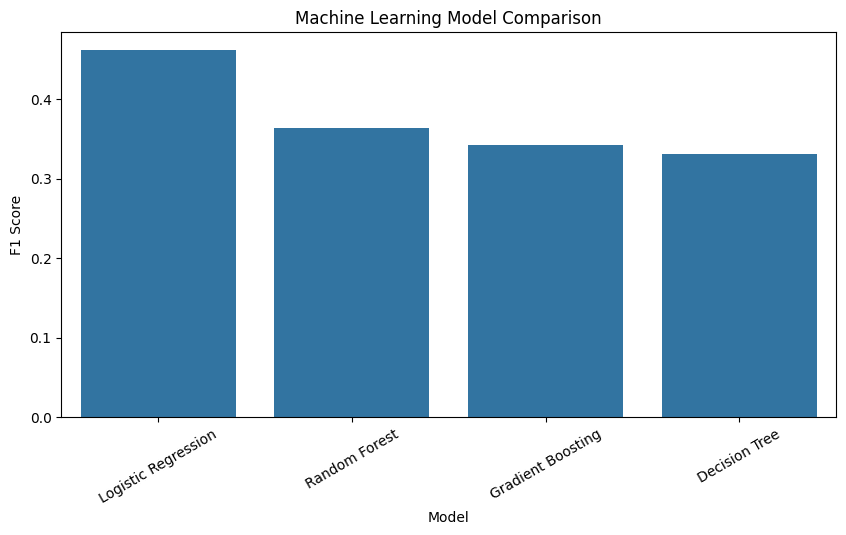

In [43]:
plt.figure(figsize=(10,5))
sns.barplot(data=results_df,x='Model',y='F1 Score')
plt.title("Machine Learning Model Comparison")
plt.xticks(rotation=30)
plt.show()

In [44]:
best_model = Pipeline(steps=[('preprocessor', preprocessor),('classifier', LogisticRegression(max_iter=1000,class_weight='balanced'))])
best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)

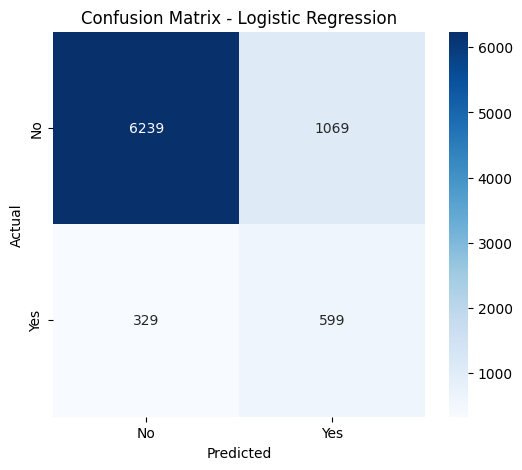

              precision    recall  f1-score   support

          No       0.95      0.85      0.90      7308
         Yes       0.36      0.65      0.46       928

    accuracy                           0.83      8236
   macro avg       0.65      0.75      0.68      8236
weighted avg       0.88      0.83      0.85      8236



In [46]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=['No', 'Yes'],yticklabels=['No', 'Yes'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()
print(classification_report(y_test, y_pred, target_names=['No', 'Yes']))

In [47]:
X_train_new, X_val, y_train_new, y_val = train_test_split(X_train,y_train,test_size=0.20,random_state=42,stratify=y_train)

In [49]:
tuned_model = Pipeline(steps=[('preprocessor', preprocessor),('classifier', LogisticRegression(max_iter=1000,class_weight='balanced'))])
tuned_model.fit(X_train_new, y_train_new)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['age', 'campaign', 'pdays', 'previous', 'emp.var.rate',
       'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'day_of_week', 'poutcome'],
      dtype='object'))])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])

In [50]:
from sklearn.metrics import f1_score
val_probabilities = tuned_model.predict_proba(X_val)[:, 1]
thresholds = np.arange(0.20, 0.71, 0.05)
threshold_results = []
for threshold in thresholds:
    val_predictions = (val_probabilities >= threshold).astype(int)
    threshold_results.append({'Threshold': threshold,'F1 Score': f1_score(y_val, val_predictions),'Precision': precision_score(y_val, val_predictions, zero_division=0),'Recall': recall_score(y_val, val_predictions, zero_division=0)})
threshold_df = pd.DataFrame(threshold_results)
threshold_df

,Threshold,F1 Score,Precision,Recall
0,0.20,0.214328,0.120386,0.975741
1,0.25,0.245300,0.141039,0.940701
2,0.30,0.275073,0.162648,0.890836
3,0.35,0.331368,0.209294,0.795148
4,0.40,0.399121,0.274007,0.734501
5,0.45,0.439414,0.327598,0.667116
6,0.50,0.470295,0.373513,0.634771
7,0.55,0.479243,0.392765,0.614555
8,0.60,0.489885,0.412144,0.603774
9,0.65,0.491456,0.436649,0.561995


In [51]:
best_threshold = threshold_df.loc[threshold_df['F1 Score'].idxmax(),'Threshold']
print("Best Threshold:", best_threshold)

Best Threshold: 0.6499999999999999


In [52]:
test_probabilities = tuned_model.predict_proba(X_test)[:, 1]
final_predictions = (test_probabilities >= best_threshold).astype(int)

In [53]:
print("Final Model Performance")
print("Accuracy:",accuracy_score(y_test, final_predictions))
print("Precision:",precision_score(y_test, final_predictions))
print("Recall:",recall_score(y_test, final_predictions))
print("F1 Score:",f1_score(y_test, final_predictions))
print("ROC-AUC:",roc_auc_score(y_test, test_probabilities))

Final Model Performance
Accuracy: 0.8729966002914036
Precision: 0.45099667774086377
Recall: 0.5851293103448276
F1 Score: 0.5093808630393997
ROC-AUC: 0.7993997632495329


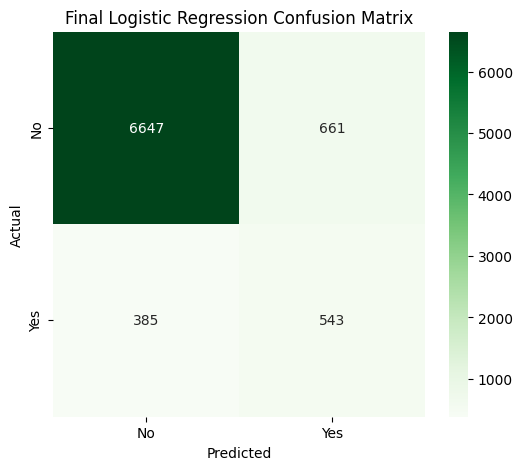

In [54]:
cm = confusion_matrix(y_test, final_predictions)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True,fmt='d',cmap='Greens',xticklabels=['No', 'Yes'],yticklabels=['No', 'Yes'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Final Logistic Regression Confusion Matrix")
plt.show()

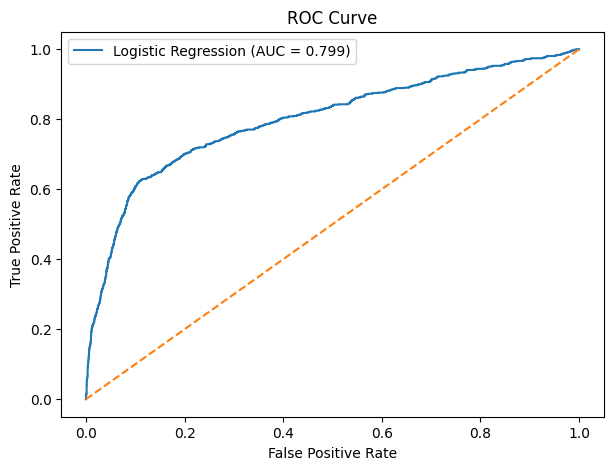

In [55]:
from sklearn.metrics import roc_curve
fpr, tpr, thresholds_roc = roc_curve(y_test,test_probabilities)
roc_auc = roc_auc_score(y_test, test_probabilities)
plt.figure(figsize=(7,5))
plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {roc_auc:.3f})')
plt.plot([0,1], [0,1], linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [56]:
feature_names = tuned_model.named_steps['preprocessor'].get_feature_names_out()
coefficients = tuned_model.named_steps['classifier'].coef_[0]
feature_importance = pd.DataFrame({'Feature': feature_names,'Coefficient': coefficients})
feature_importance['Absolute Importance'] = (feature_importance['Coefficient'].abs())
feature_importance = feature_importance.sort_values(by='Absolute Importance',ascending=False)
feature_importance.head(15)

,Feature,Coefficient,Absolute Importance
4,num__emp.var.rate,-1.977340,1.977340
49,cat__month_mar,1.243673,1.243673
5,num__cons.price.idx,0.973457,0.973457
50,cat__month_may,-0.655096,0.655096
48,cat__month_jun,-0.618845,0.618845
51,cat__month_nov,-0.497497,0.497497
59,cat__poutcome_failure,-0.396921,0.396921
14,cat__job_retired,0.388912,0.388912
29,cat__education_illiterate,0.386237,0.386237
61,cat__poutcome_success,0.382764,0.382764


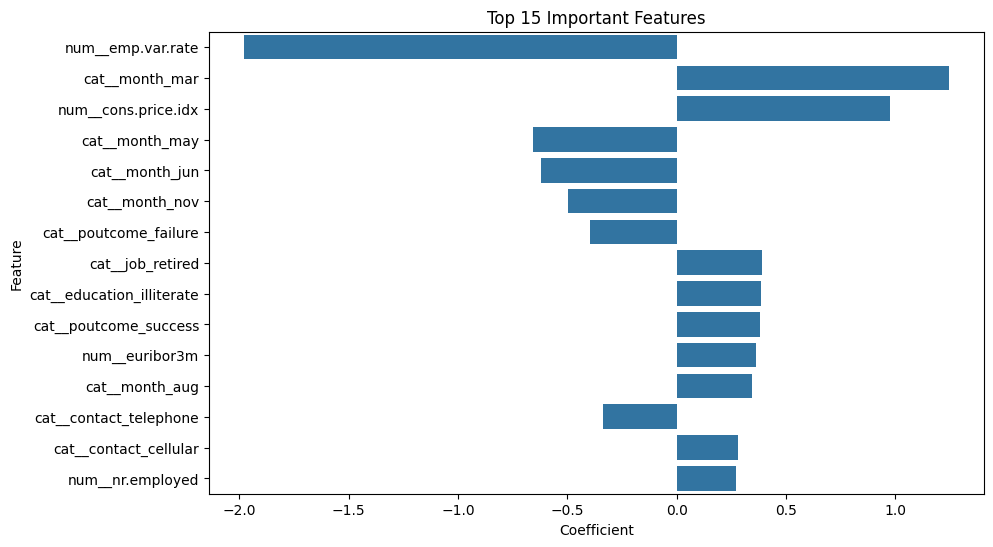

In [57]:
top_features = feature_importance.head(15)
plt.figure(figsize=(10,6))
sns.barplot(data=top_features,x='Coefficient',y='Feature')
plt.title("Top 15 Important Features")
plt.show()

In [58]:
new_customer = pd.DataFrame([{
    'age': 35,
    'job': 'admin.',
    'marital': 'married',
    'education': 'university.degree',
    'default': 'no',
    'housing': 'yes',
    'loan': 'no',
    'contact': 'cellular',
    'month': 'may',
    'day_of_week': 'mon',
    'campaign': 1,
    'pdays': 999,
    'previous': 0,
    'poutcome': 'nonexistent',
    'emp.var.rate': -1.8,
    'cons.price.idx': 92.8,
    'cons.conf.idx': -40.0,
    'euribor3m': 1.3,
    'nr.employed': 5099.1}])
probability = tuned_model.predict_proba(new_customer)[0][1]
prediction = ('Yes' if probability >= best_threshold else 'No')
print("Subscription Prediction:", prediction)
print("Subscription Probability:", round(probability * 100, 2), "%")

Subscription Prediction: No
Subscription Probability: 45.58 %


# **Challenges**

1.   Imbalanced dataset
2.   Different feature scales
3.   Unknown categorical values
4.   Data leakage risk
5.   Low recall in some models



# **Solutions**

1.   Used class weighting in Logistic Regression
2.   Applied StandardScaler
3.   Retained them as separate categories
4.   Removed the duration feature
5.   Compared multiple models and tuned the classification threshold



# **Conclusions**
In this project, I developed a Machine Learning-based Portuguese Bank Marketing Prediction system to predict whether customers are likely to subscribe to a term deposit.I performed data cleaning, exploratory data analysis, feature selection, data preprocessing, and model training. I implemented four machine learning algorithms: Logistic Regression, Decision Tree, Random Forest, and Gradient Boosting.

Among the four models, Logistic Regression achieved the highest F1-score of 46.15% and recall of 64.55% in the initial evaluation. I further improved the model by optimizing its classification threshold using validation data.
The final model can help the bank identify potential customers, improve marketing campaign efficiency, and make data-driven decisions.